In [10]:
!pip -q install gwpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 20.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.2/45.2 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.1/114.1 kB 3.6 MB/s eta 0:00:00


In [11]:
from gwpy.timeseries import TimeSeries
import matplotlib.pyplot as plt

In [12]:
event_time = 1126259462

h1 = TimeSeries.fetch_open_data(
    "H1",
    event_time - 16,
    event_time + 16,
    cache=False
)

l1 = TimeSeries.fetch_open_data(
    "L1",
    event_time - 16,
    event_time + 16,
    cache=False
)

In [13]:
# Basic information about the data

print("========== Hanford (H1) ==========")
print(h1)

print("\n========== Livingston (L1) ==========")
print(l1)

print("\n========== Dataset Summary ==========")

print(f"Number of H1 samples : {len(h1):,}")
print(f"Number of L1 samples : {len(l1):,}")

print(f"\nSampling Rate : {h1.sample_rate}")

print(f"Time Interval (dt) : {h1.dt}")

print(f"Recording Duration : {h1.duration}")

print(f"Start Time : {h1.t0}")

print(f"End Time : {h1.span[1]}")

========== Hanford (H1) ==========
TimeSeries([2.17704028e-19, 2.08763900e-19, 2.39681183e-19, ...,
            3.55365541e-20, 6.33533516e-20, 7.58121195e-20],
           unit: dimensionless,
           dtype: float64,
           t0: 1126259446.0 s,
           dt: 0.000244140625 s,
           name: H1:Strain,
           channel: None)

========== Livingston (L1) ==========
TimeSeries([-1.04289994e-18, -1.03586274e-18, -9.89322445e-19,
            ..., -1.01767748e-18, -9.82876815e-19,
            -9.59276974e-19],
           unit: dimensionless,
           dtype: float64,
           t0: 1126259446.0 s,
           dt: 0.000244140625 s,
           name: L1:Strain,
           channel: None)

========== Dataset Summary ==========
Number of H1 samples : 131,072
Number of L1 samples : 131,072

Sampling Rate : 4096.0 Hz
Time Interval (dt) : 0.000244140625 s
Recording Duration : 32.0 s
Start Time : 1126259446.0 s
End Time : 1126259478.0


## Visualizing the Raw Gravitational Wave Signal

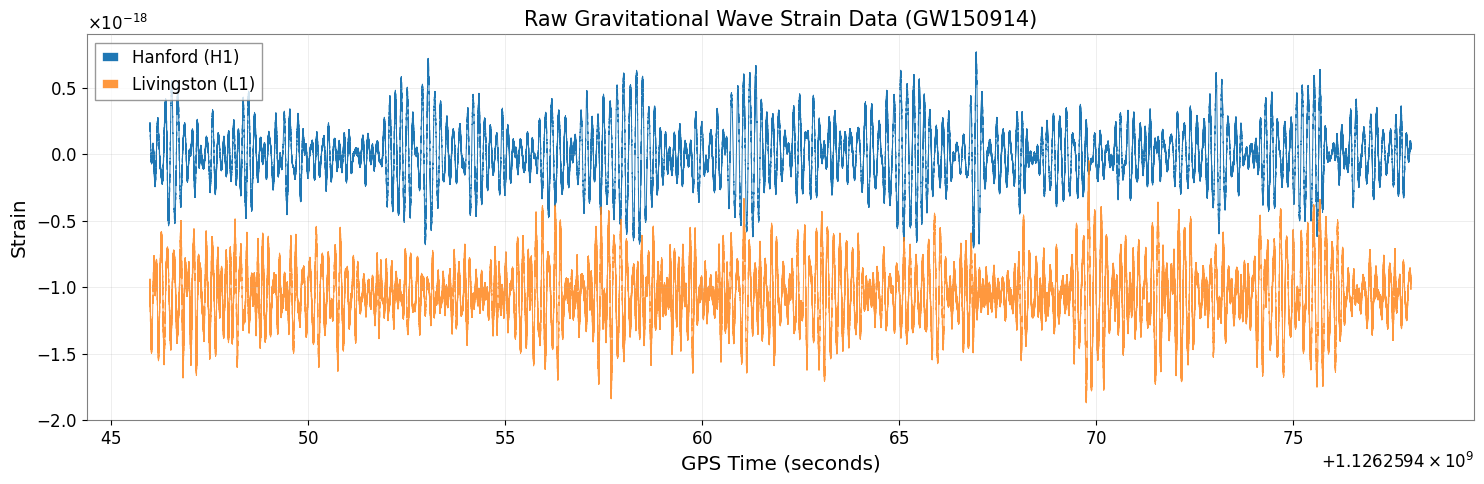

In [14]:
plt.figure(figsize=(15,5))

plt.plot(
    h1.times.value,
    h1.value,
    label="Hanford (H1)",
    linewidth=0.7
)

plt.plot(
    l1.times.value,
    l1.value,
    label="Livingston (L1)",
    linewidth=0.7,
    alpha=0.8
)

plt.title("Raw Gravitational Wave Strain Data (GW150914)", fontsize=15)

plt.xlabel("GPS Time (seconds)")
plt.ylabel("Strain")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [15]:
# Apply a Band-Pass Filter

# Keep only frequencies between 30 Hz and 400 Hz
h1_filtered = h1.bandpass(30, 400)
l1_filtered = l1.bandpass(30, 400)

print("Filtering completed successfully!")


Filtering completed successfully!


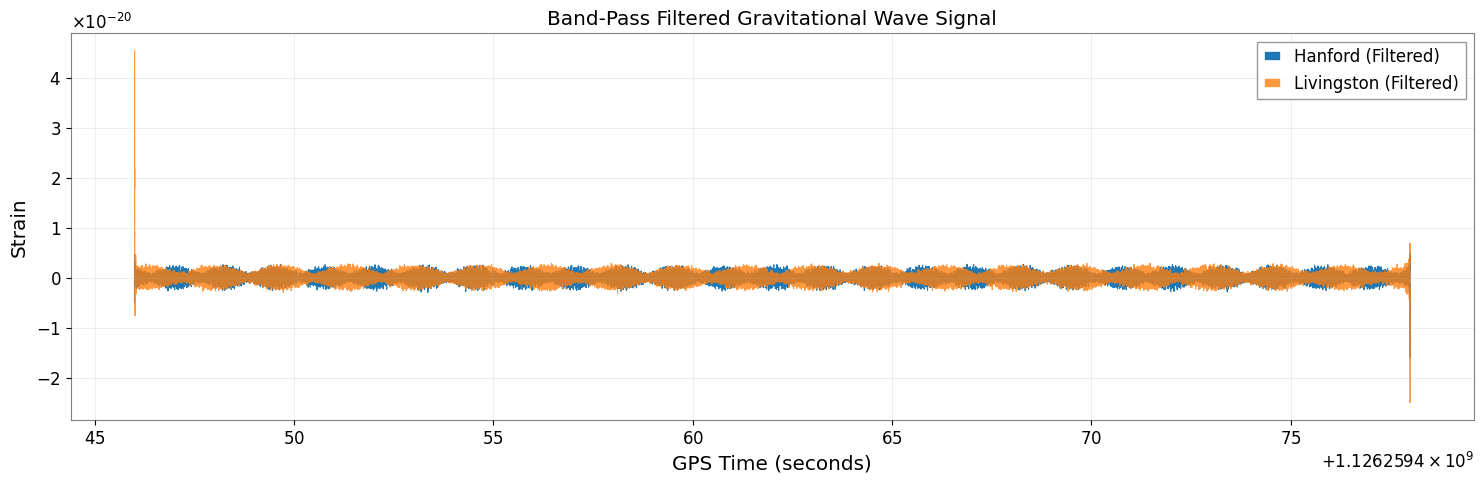

In [16]:
plt.figure(figsize=(15,5))

plt.plot(
    h1_filtered.times.value,
    h1_filtered.value,
    label="Hanford (Filtered)",
    linewidth=0.8
)

plt.plot(
    l1_filtered.times.value,
    l1_filtered.value,
    label="Livingston (Filtered)",
    linewidth=0.8,
    alpha=0.8
)

plt.title("Band-Pass Filtered Gravitational Wave Signal")

plt.xlabel("GPS Time (seconds)")
plt.ylabel("Strain")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()


# Zoom into the merger event

In [17]:
event_time = 1126259462.4

h1_zoom = h1_filtered.crop(
    event_time - 0.2,
    event_time + 0.2
)

l1_zoom = l1_filtered.crop(
    event_time - 0.2,
    event_time + 0.2
)

print("H1 zoom samples:", len(h1_zoom))
print("L1 zoom samples:", len(l1_zoom))

H1 zoom samples: 1638
L1 zoom samples: 1638


## Plot the zoomed waveform

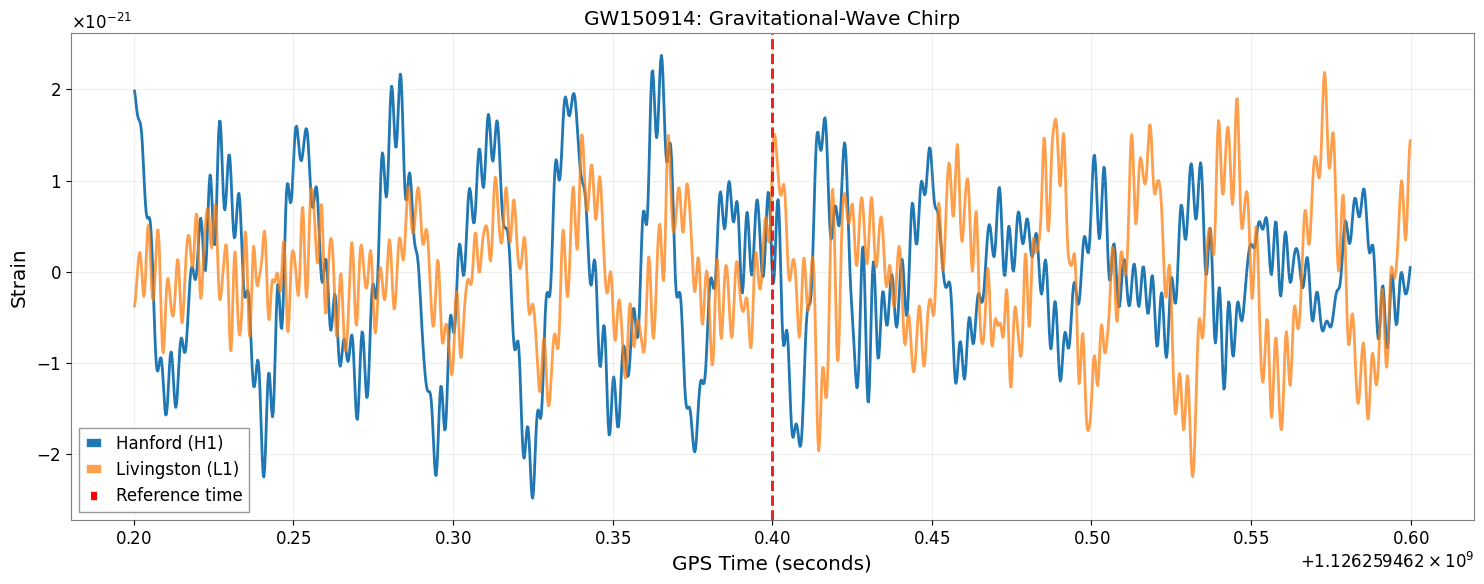

In [18]:
plt.figure(figsize=(15, 6))

plt.plot(
    h1_zoom.times.value,
    h1_zoom.value,
    label="Hanford (H1)",
    linewidth=2
)

plt.plot(
    l1_zoom.times.value,
    l1_zoom.value,
    label="Livingston (L1)",
    linewidth=2,
    alpha=0.75
)

plt.axvline(
    event_time,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Reference time"
)

plt.title("GW150914: Gravitational-Wave Chirp")
plt.xlabel("GPS Time (seconds)")
plt.ylabel("Strain")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Visualizing the Gravitational-Wave Chirp

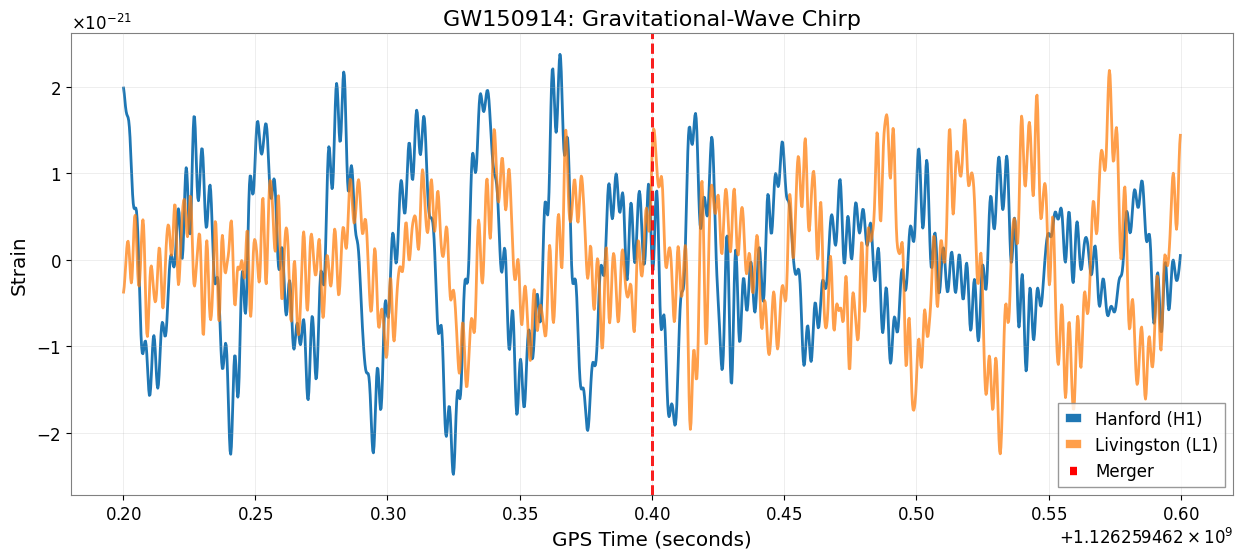

In [19]:
plt.figure(figsize=(15,6))

plt.plot(
    h1_zoom.times.value,
    h1_zoom.value,
    label="Hanford (H1)",
    linewidth=2
)

plt.plot(
    l1_zoom.times.value,
    l1_zoom.value,
    label="Livingston (L1)",
    linewidth=2,
    alpha=0.75
)

plt.axvline(
    event_time,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Merger"
)

plt.title("GW150914: Gravitational-Wave Chirp", fontsize=16)

plt.xlabel("GPS Time (seconds)")
plt.ylabel("Strain")

plt.grid(alpha=0.3)
plt.legend()

plt.show()



## Measuring the Gravitational-Wave Signal

In [20]:
import numpy as np

# Peak strain values
h1_peak = np.max(np.abs(h1_zoom.value))
l1_peak = np.max(np.abs(l1_zoom.value))

print(f"Maximum H1 strain : {h1_peak:.3e}")
print(f"Maximum L1 strain : {l1_peak:.3e}")

Maximum H1 strain : 2.480e-21
Maximum L1 strain : 2.243e-21


## Calculate the signal envelope

In [21]:
from scipy.signal import hilbert, find_peaks

# Extract the observed Hanford waveform
signal = np.asarray(h1_zoom.value)
times = np.asarray(h1_zoom.times.value)

# Compute the analytic signal
analytic_signal = hilbert(signal)

# Calculate the amplitude envelope
envelope = np.abs(analytic_signal)

print("Signal envelope calculated successfully!")
print(f"Number of samples: {len(envelope)}")
print(f"Maximum envelope amplitude: {np.max(envelope):.3e}")

Signal envelope calculated successfully!
Number of samples: 1638
Maximum envelope amplitude: 2.913e-21


## Plot the observed waveform and its envelope

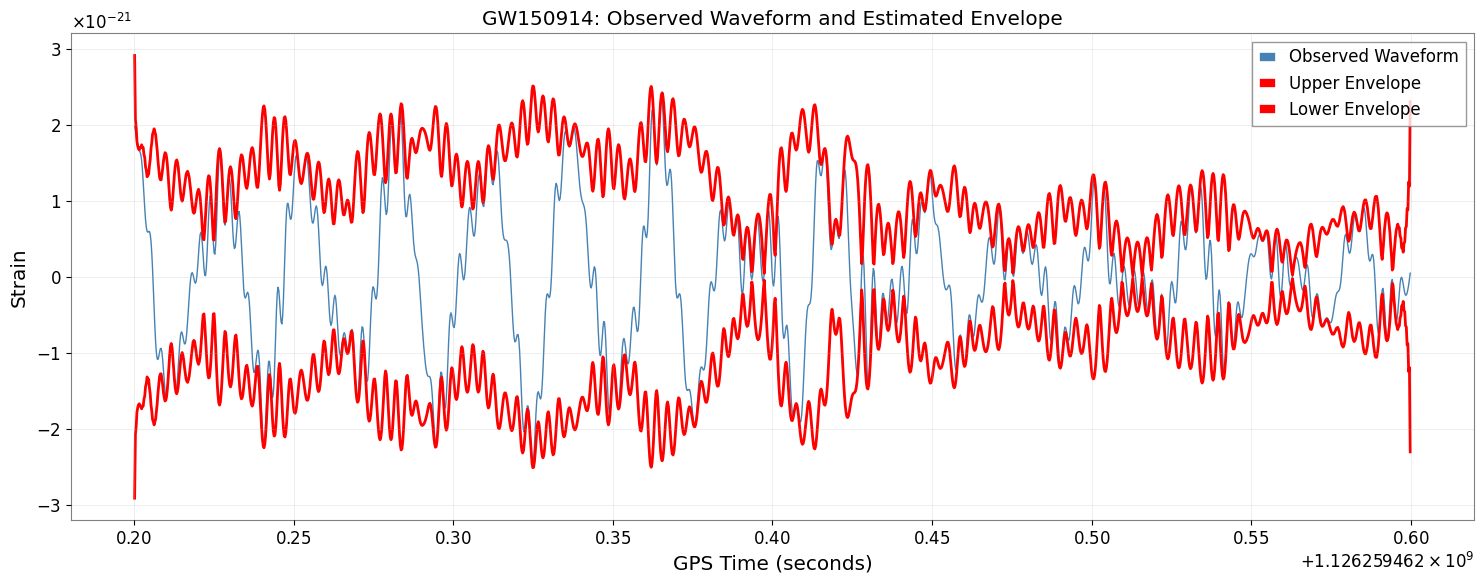

In [22]:
plt.figure(figsize=(15, 6))

plt.plot(
    times,
    signal,
    color="steelblue",
    linewidth=1,
    label="Observed Waveform"
)

plt.plot(
    times,
    envelope,
    color="red",
    linewidth=2,
    label="Upper Envelope"
)

plt.plot(
    times,
    -envelope,
    color="red",
    linewidth=2,
    label="Lower Envelope"
)

plt.title("GW150914: Observed Waveform and Estimated Envelope")
plt.xlabel("GPS Time (seconds)")
plt.ylabel("Strain")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Estimate the instantaneous frequency from waveform peaks

In [23]:
# Detect prominent positive peaks
peaks, properties = find_peaks(
    signal,
    distance=10,
    prominence=0.5 * np.std(signal)
)

peak_times = times[peaks]

# Calculate periods between consecutive peaks
periods = np.diff(peak_times)

# Convert periods into frequency estimates
frequencies = 1.0 / periods

# Assign each estimate to the midpoint between its peaks
frequency_times = (
    peak_times[:-1] + peak_times[1:]
) / 2

if len(frequencies) == 0:
    raise ValueError(
        "Too few peaks detected. Adjust the peak detection settings."
    )

print(f"Detected peaks: {len(peaks)}")
print(f"Frequency estimates: {len(frequencies)}")
print(f"Estimated frequency range: "
      f"{np.min(frequencies):.2f}–{np.max(frequencies):.2f} Hz")

Detected peaks: 51
Frequency estimates: 50
Estimated frequency range: 37.24–372.36 Hz


# Plot the estimated frequency evolution

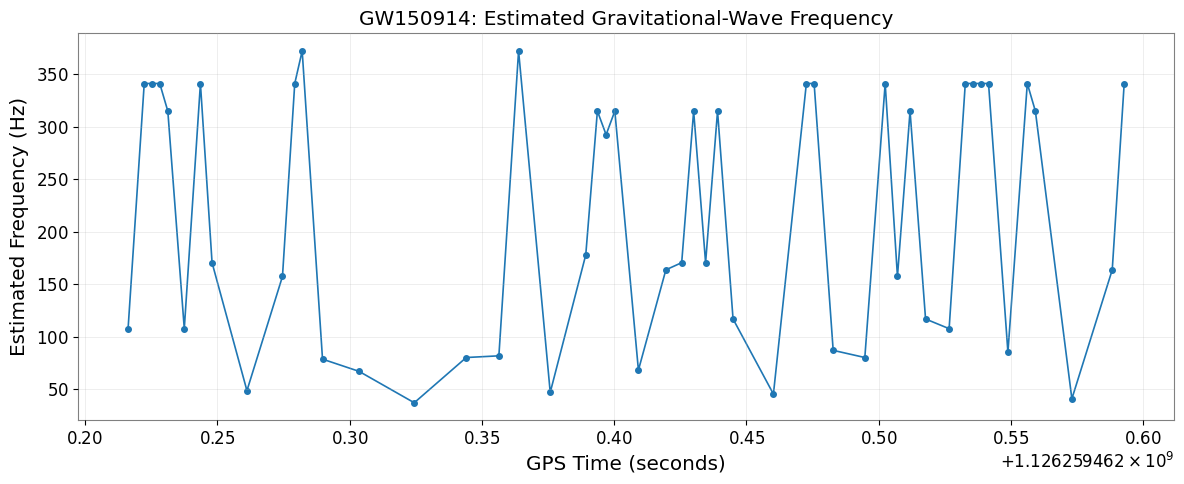

In [24]:
plt.figure(figsize=(12, 5))

plt.plot(
    frequency_times,
    frequencies,
    marker="o",
    markersize=4,
    linewidth=1.2
)

plt.title("GW150914: Estimated Gravitational-Wave Frequency")
plt.xlabel("GPS Time (seconds)")
plt.ylabel("Estimated Frequency (Hz)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Plot the measured frequency evolution

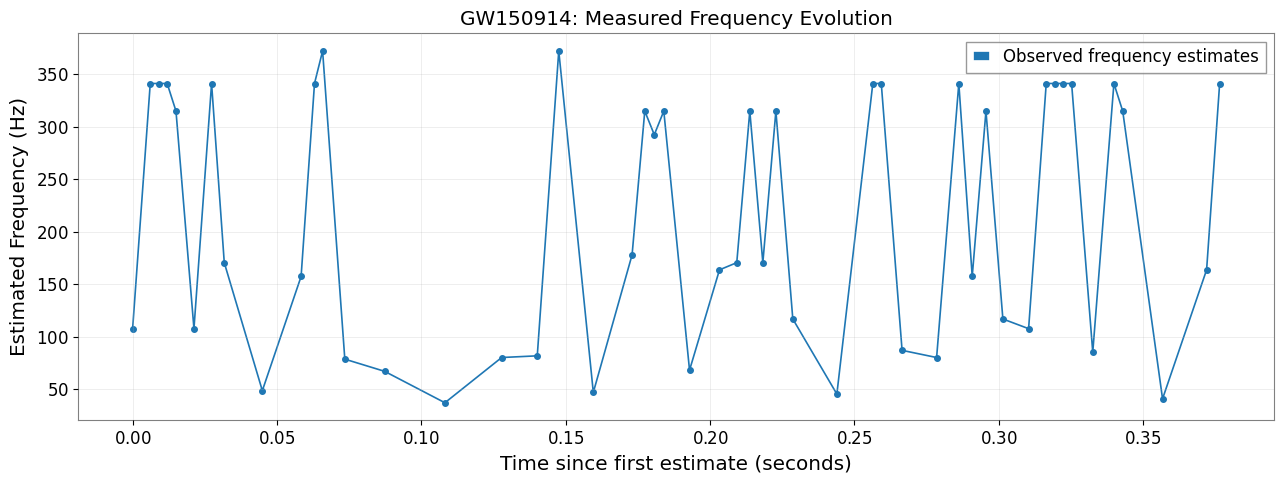

In [25]:
# Sort measured frequency estimates chronologically
sort_idx = np.argsort(frequency_times)

frequency_times = np.asarray(frequency_times)[sort_idx]
frequencies = np.asarray(frequencies)[sort_idx]

# Plot measured estimates only
plt.figure(figsize=(13, 5))

plt.plot(
    frequency_times - frequency_times.min(),
    frequencies,
    "o-",
    markersize=4,
    linewidth=1.2,
    label="Observed frequency estimates"
)

plt.xlabel("Time since first estimate (seconds)")
plt.ylabel("Estimated Frequency (Hz)")
plt.title("GW150914: Measured Frequency Evolution")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Generate a theoretical waveform using PyCBC

In [26]:
!pip install pycbc -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 64.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.6/168.6 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 MB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.1/203.1 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.5/53.5 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.1/48.1 MB 14.0 MB/s eta 0:00:00


In [27]:
from pycbc.waveform import get_td_waveform

# Generate a general-relativistic binary black hole waveform
hp, hc = get_td_waveform(
    approximant="IMRPhenomD",
    mass1=36,
    mass2=29,
    delta_t=1 / 4096,
    f_lower=20
)

# Convert the plus polarization to NumPy arrays
hp_data = hp.numpy()
hp_time = hp.sample_times.numpy()

# Identify the waveform's maximum-amplitude sample
peak_idx = np.argmax(np.abs(hp_data))

# Set the theoretical merger peak to t = 0
theory_time = hp_time - hp_time[peak_idx]

print("Theoretical waveform generated successfully.")
print(f"Number of samples: {len(hp_data):,}")
print(f"Sampling rate: {1 / hp.delta_t:.0f} Hz")
print(f"Duration: {float(hp.duration):.2f} seconds")
print(f"Peak amplitude before normalization: {np.max(np.abs(hp_data)):.3e}")

/usr/lib/python3.13/importlib/__init__.py:88: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  return _bootstrap._gcd_import(name[level:], package, level)


Theoretical waveform generated successfully.
Number of samples: 65,536
Sampling rate: 4096 Hz
Duration: 16.00 seconds
Peak amplitude before normalization: 7.539e-19


## Plot the complete theoretical waveform

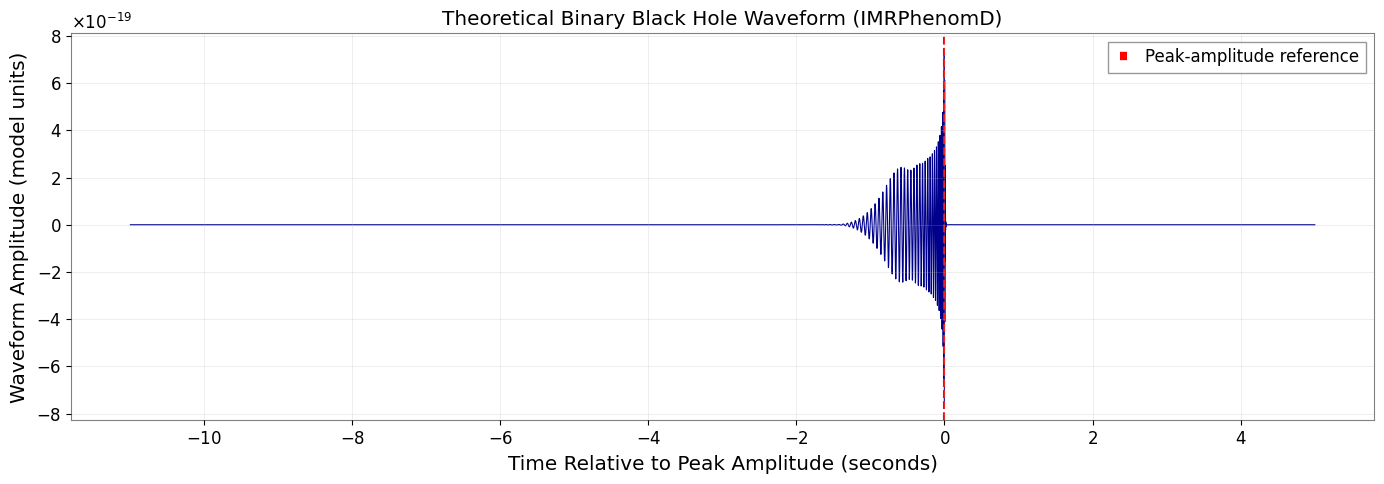

In [28]:
plt.figure(figsize=(14, 5))

plt.plot(
    theory_time,
    hp_data,
    linewidth=0.8,
    color="darkblue"
)

plt.axvline(0, color="red", linestyle="--", label="Peak-amplitude reference")

plt.title("Theoretical Binary Black Hole Waveform (IMRPhenomD)")
plt.xlabel("Time Relative to Peak Amplitude (seconds)")
plt.ylabel("Waveform Amplitude (model units)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Normalize the theoretical waveform and inspect its final second

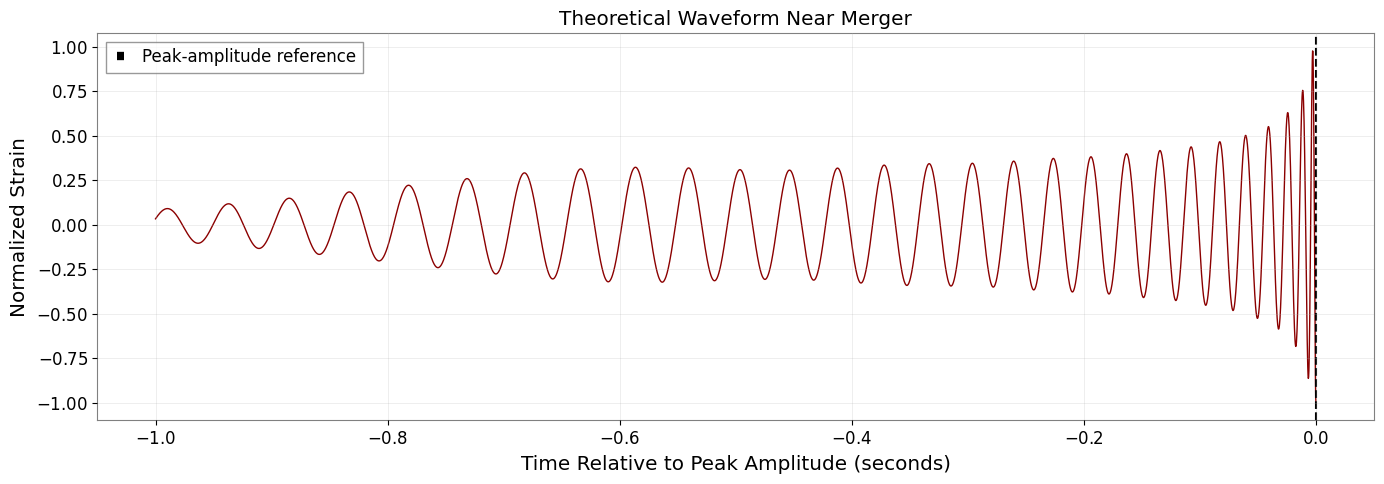

In [29]:
# Normalize by the maximum absolute amplitude
hp_norm = hp_data / np.max(np.abs(hp_data))

# Select the final second relative to the peak-amplitude reference
final_second = (theory_time >= -1.0) & (theory_time <= 0.0)

plt.figure(figsize=(14, 5))

plt.plot(
    theory_time[final_second],
    hp_norm[final_second],
    color="darkred",
    linewidth=1
)

plt.axvline(0, color="black", linestyle="--", label="Peak-amplitude reference")

plt.title("Theoretical Waveform Near Merger")
plt.xlabel("Time Relative to Peak Amplitude (seconds)")
plt.ylabel("Normalized Strain")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Prepare both waveforms for a fairer visual comparison

In [30]:
from scipy.signal import butter, sosfiltfilt

sample_rate = 4096

# Filter the theoretical waveform using the observed frequency band
sos = butter(
    4,
    [30, 400],
    btype="bandpass",
    fs=sample_rate,
    output="sos"
)

hp_filtered = sosfiltfilt(sos, hp_data)

# Normalize the theoretical waveform
hp_filtered_norm = hp_filtered / np.max(np.abs(hp_filtered))

# Prepare the observed Hanford waveform
obs = np.asarray(h1_zoom.value, dtype=float)
obs_norm = obs / np.max(np.abs(obs))
obs_times = np.asarray(h1_zoom.times.value)

# Locate the maximum absolute amplitude in each waveform
obs_peak_idx = np.argmax(np.abs(obs_norm))
theory_peak_idx = np.argmax(np.abs(hp_filtered_norm))

# Align both peak-amplitude samples to t = 0
obs_time_aligned = obs_times - obs_times[obs_peak_idx]
theory_time_aligned = (
    hp.sample_times.numpy()
    - hp.sample_times.numpy()[theory_peak_idx]
)

print("Both waveform peaks aligned to t = 0.")
print(f"Observed peak GPS time: {obs_times[obs_peak_idx]:.6f}")
print(f"Observed samples: {len(obs_norm):,}")
print(f"Theoretical samples: {len(hp_filtered_norm):,}")

Both waveform peaks aligned to t = 0.
Observed peak GPS time: 1126259462.324951
Observed samples: 1,638
Theoretical samples: 65,536


## Compare observed and theoretical waveform shapes

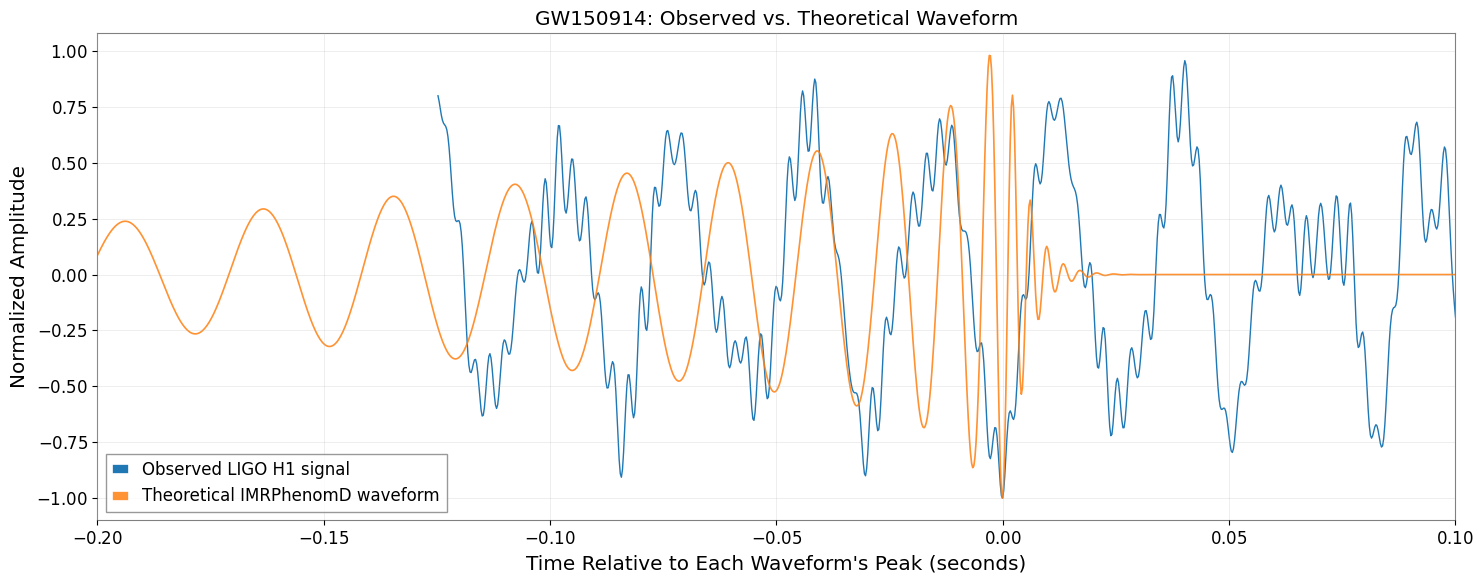

In [31]:
plt.figure(figsize=(15, 6))

plt.plot(
    obs_time_aligned,
    obs_norm,
    label="Observed LIGO H1 signal",
    linewidth=1
)

plt.plot(
    theory_time_aligned,
    hp_filtered_norm,
    label="Theoretical IMRPhenomD waveform",
    linewidth=1.2,
    alpha=0.85
)

plt.xlim(-0.2, 0.1)

plt.xlabel("Time Relative to Each Waveform's Peak (seconds)")
plt.ylabel("Normalized Amplitude")
plt.title("GW150914: Observed vs. Theoretical Waveform")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Characterize detector noise

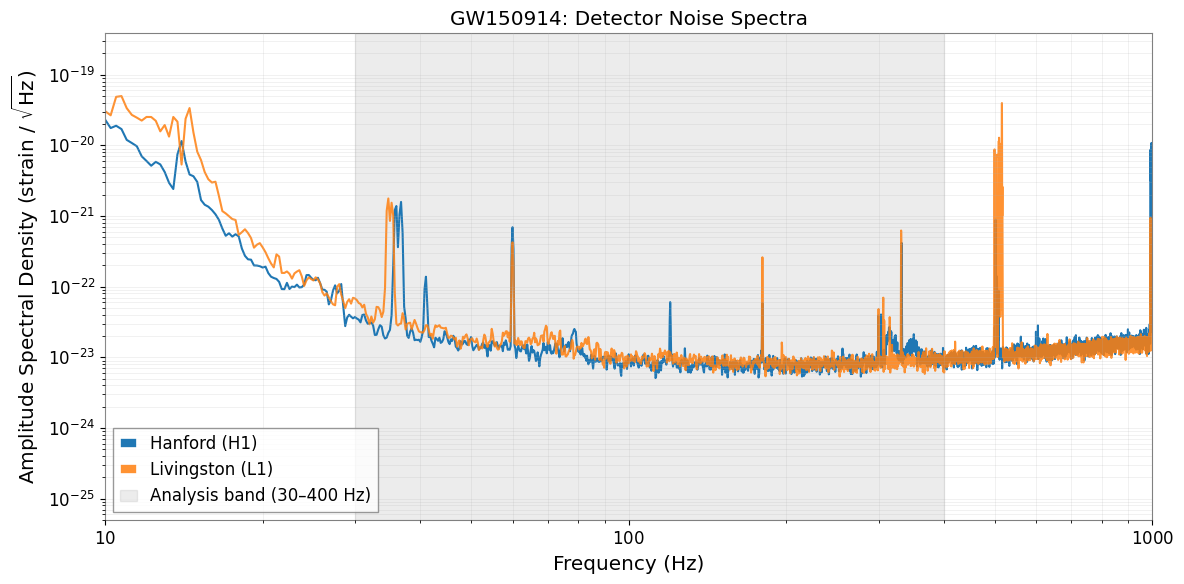

PSD and ASD estimation completed.
Sampling rate: 4096 Hz
H1 PSD array length: 8,193
L1 PSD array length: 8,193


In [33]:
from scipy.signal import welch

# Sampling rate — explicitly convert Hz to a plain number
fs = h1.sample_rate.to_value("Hz")

# Convert strain data to NumPy arrays
h1_data = np.asarray(h1.value, dtype=float)
l1_data = np.asarray(l1.value, dtype=float)

# Estimate power spectral density (PSD)
nperseg = int(fs * 4)  # 4-second segments

frequencies_h1, psd_h1 = welch(
    h1_data,
    fs=fs,
    window="hann",
    nperseg=nperseg,
    detrend="constant",
    scaling="density"
)

frequencies_l1, psd_l1 = welch(
    l1_data,
    fs=fs,
    window="hann",
    nperseg=nperseg,
    detrend="constant",
    scaling="density"
)

# Convert PSD to amplitude spectral density (ASD)
asd_h1 = np.sqrt(psd_h1)
asd_l1 = np.sqrt(psd_l1)

# Plot detector noise spectra
plt.figure(figsize=(12, 6))

plt.loglog(
    frequencies_h1[1:],
    asd_h1[1:],
    label="Hanford (H1)"
)

plt.loglog(
    frequencies_l1[1:],
    asd_l1[1:],
    label="Livingston (L1)",
    alpha=0.85
)

plt.axvspan(
    30, 400,
    color="gray",
    alpha=0.15,
    label="Analysis band (30–400 Hz)"
)

plt.xlim(10, 1000)
plt.xlabel("Frequency (Hz)")
plt.ylabel(r"Amplitude Spectral Density (strain / $\sqrt{\mathrm{Hz}}$)")
plt.title("GW150914: Detector Noise Spectra")
plt.grid(True, which="both", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

print("PSD and ASD estimation completed.")
print(f"Sampling rate: {fs:.0f} Hz")
print(f"H1 PSD array length: {len(psd_h1):,}")
print(f"L1 PSD array length: {len(psd_l1):,}")

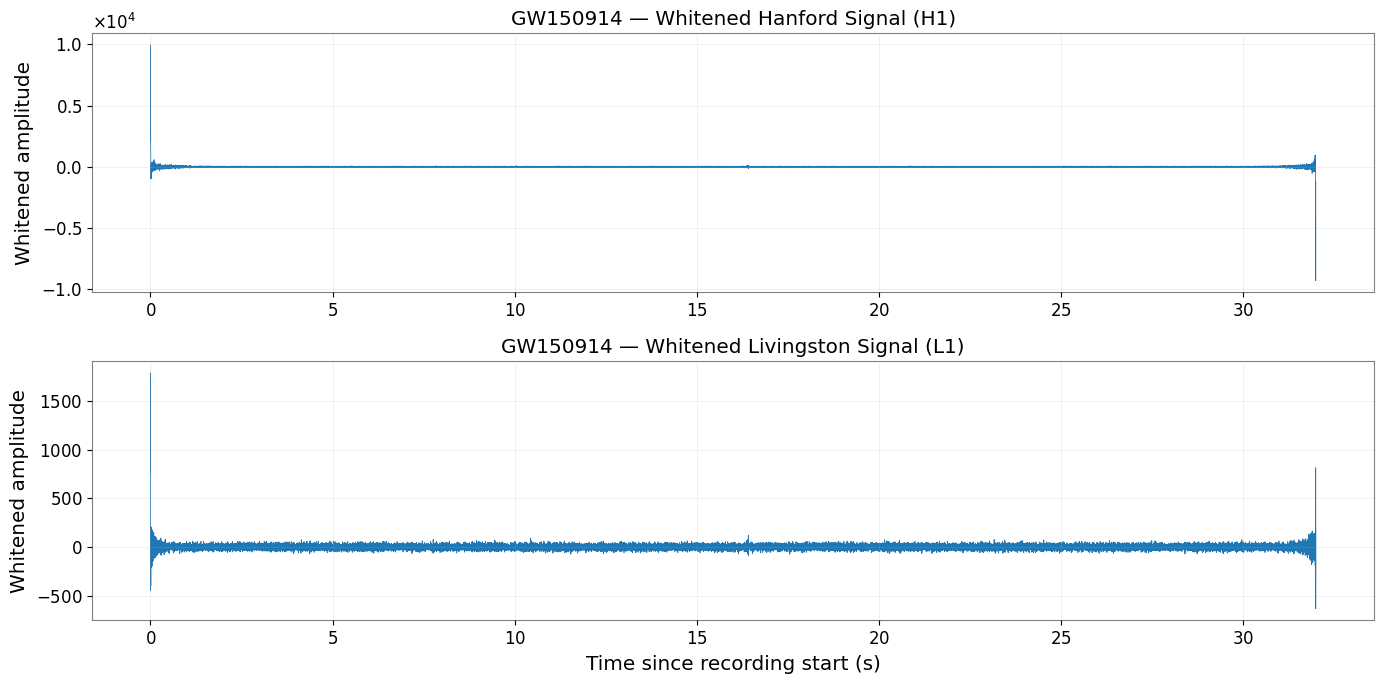

Whitening completed for H1 and L1.
Sampling rate: 4096 Hz
H1 whitened samples: 131,072
L1 whitened samples: 131,072


In [35]:
# Explicitly convert GWpy's unit-aware sampling rate
fs = float(h1.sample_rate.to_value("Hz"))

h1_data = np.asarray(h1.value, dtype=float)
l1_data = np.asarray(l1.value, dtype=float)

nperseg = int(fs * 4)

freq_h1, psd_h1 = welch(
    h1_data, fs=fs, window="hann",
    nperseg=nperseg, detrend="constant",
    scaling="density"
)

freq_l1, psd_l1 = welch(
    l1_data, fs=fs, window="hann",
    nperseg=nperseg, detrend="constant",
    scaling="density"
)

def whiten_signal(data, psd_freq, psd, fs):
    n = len(data)
    fft_freq = np.fft.rfftfreq(n, d=1 / fs)
    data_fft = np.fft.rfft(data - np.mean(data))

    psd_interp = np.interp(fft_freq, psd_freq, psd)

    valid = (
        (psd_interp > 0)
        & (fft_freq >= 30)
        & (fft_freq <= 400)
    )

    whitened_fft = np.zeros_like(data_fft, dtype=complex)
    whitened_fft[valid] = (
        data_fft[valid] / np.sqrt(psd_interp[valid])
    )

    return np.fft.irfft(whitened_fft, n=n)

h1_white = whiten_signal(h1_data, freq_h1, psd_h1, fs)
l1_white = whiten_signal(l1_data, freq_l1, psd_l1, fs)

time_h1 = np.arange(len(h1_white)) / fs
time_l1 = np.arange(len(l1_white)) / fs

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

axes[0].plot(time_h1, h1_white, linewidth=0.6)
axes[0].set_title("GW150914 — Whitened Hanford Signal (H1)")
axes[0].set_ylabel("Whitened amplitude")
axes[0].grid(alpha=0.25)

axes[1].plot(time_l1, l1_white, linewidth=0.6)
axes[1].set_title("GW150914 — Whitened Livingston Signal (L1)")
axes[1].set_xlabel("Time since recording start (s)")
axes[1].set_ylabel("Whitened amplitude")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("Whitening completed for H1 and L1.")
print(f"Sampling rate: {fs:.0f} Hz")
print(f"H1 whitened samples: {len(h1_white):,}")
print(f"L1 whitened samples: {len(l1_white):,}")

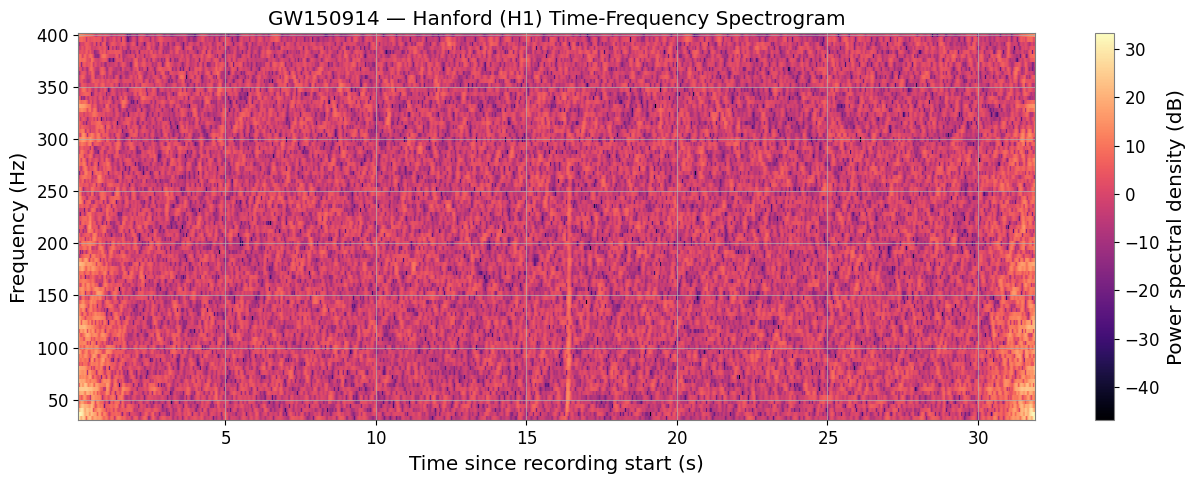

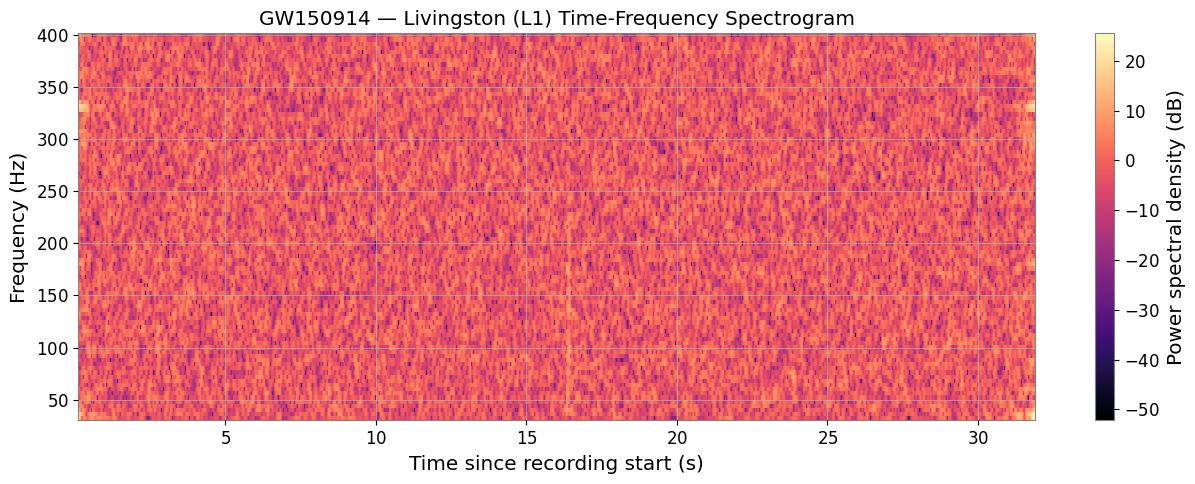

Time-frequency spectrograms generated for both detectors.


In [40]:
from scipy.signal import spectrogram

fs = float(h1.sample_rate.to_value("Hz"))

def plot_spectrogram(data, detector_name):
    frequencies, times, power = spectrogram(
        data,
        fs=fs,
        window="hann",
        nperseg=1024,
        noverlap=896,
        detrend="constant",
        scaling="density",
        mode="psd"
    )

    # Display only the main analysis band
    mask = (frequencies >= 30) & (frequencies <= 400)

    plt.figure(figsize=(13, 5))
    plt.pcolormesh(
        times,
        frequencies[mask],
        10 * np.log10(power[mask, :] + 1e-60),
        shading="auto",
        cmap="magma"
    )
    plt.xlabel("Time since recording start (s)")
    plt.ylabel("Frequency (Hz)")
    plt.title(f"GW150914 — {detector_name} Time-Frequency Spectrogram")
    plt.colorbar(label="Power spectral density (dB)")
    plt.tight_layout()
    plt.show()

plot_spectrogram(h1_white, "Hanford (H1)")
plot_spectrogram(l1_white, "Livingston (L1)")

print("Time-frequency spectrograms generated for both detectors.")

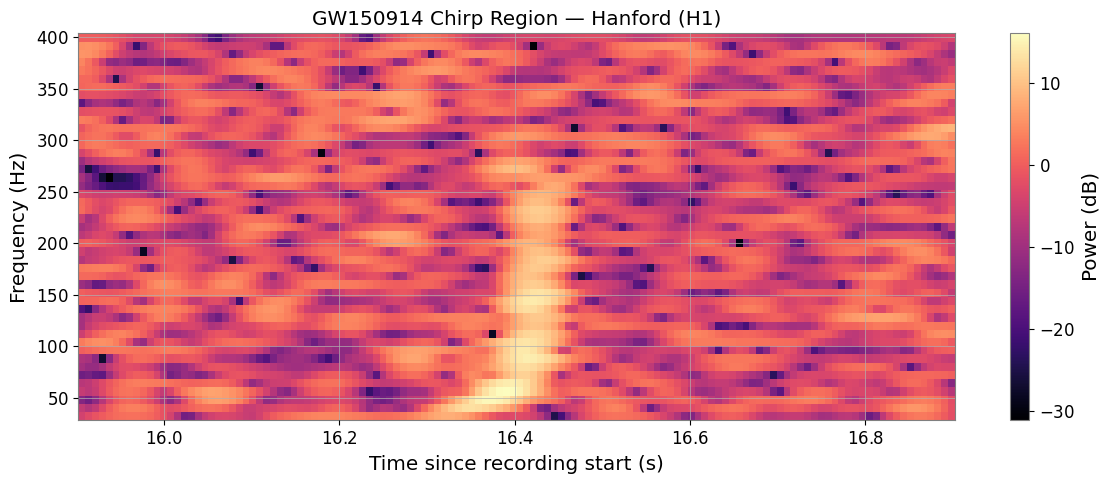

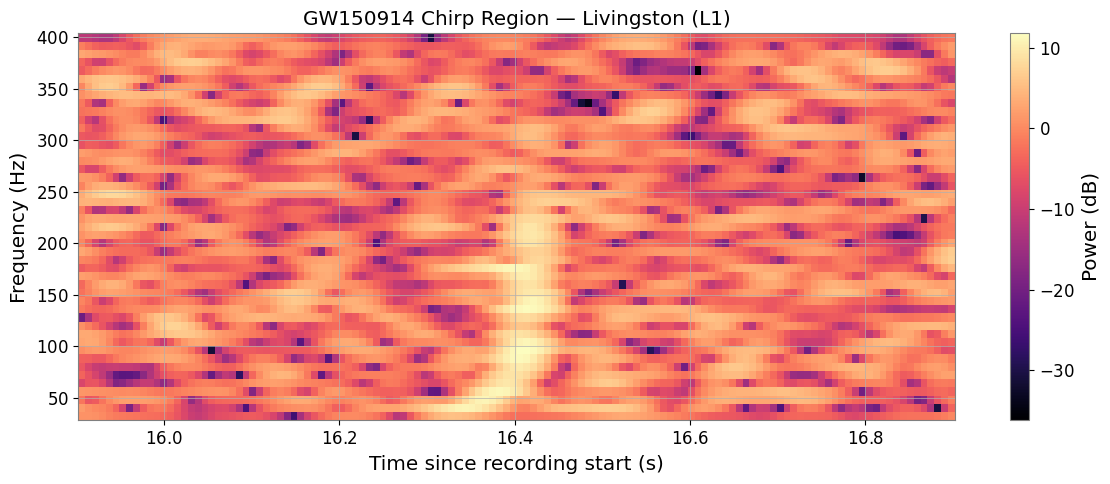

In [37]:
# Zoom around the GW150914 event
event_relative_time = 16.4
window = 0.5  # seconds on each side

for data, detector in [
    (h1_white, "Hanford (H1)"),
    (l1_white, "Livingston (L1)")
]:
    frequencies, times, power = spectrogram(
        data,
        fs=fs,
        window="hann",
        nperseg=512,
        noverlap=480,
        scaling="density",
        mode="psd"
    )

    time_mask = (
        (times >= event_relative_time - window) &
        (times <= event_relative_time + window)
    )
    freq_mask = (frequencies >= 30) & (frequencies <= 400)

    plt.figure(figsize=(12, 5))
    plt.pcolormesh(
        times[time_mask],
        frequencies[freq_mask],
        10 * np.log10(power[np.ix_(freq_mask, time_mask)] + 1e-60),
        shading="auto",
        cmap="magma"
    )
    plt.xlabel("Time since recording start (s)")
    plt.ylabel("Frequency (Hz)")
    plt.title(f"GW150914 Chirp Region — {detector}")
    plt.colorbar(label="Power (dB)")
    plt.tight_layout()
    plt.show()

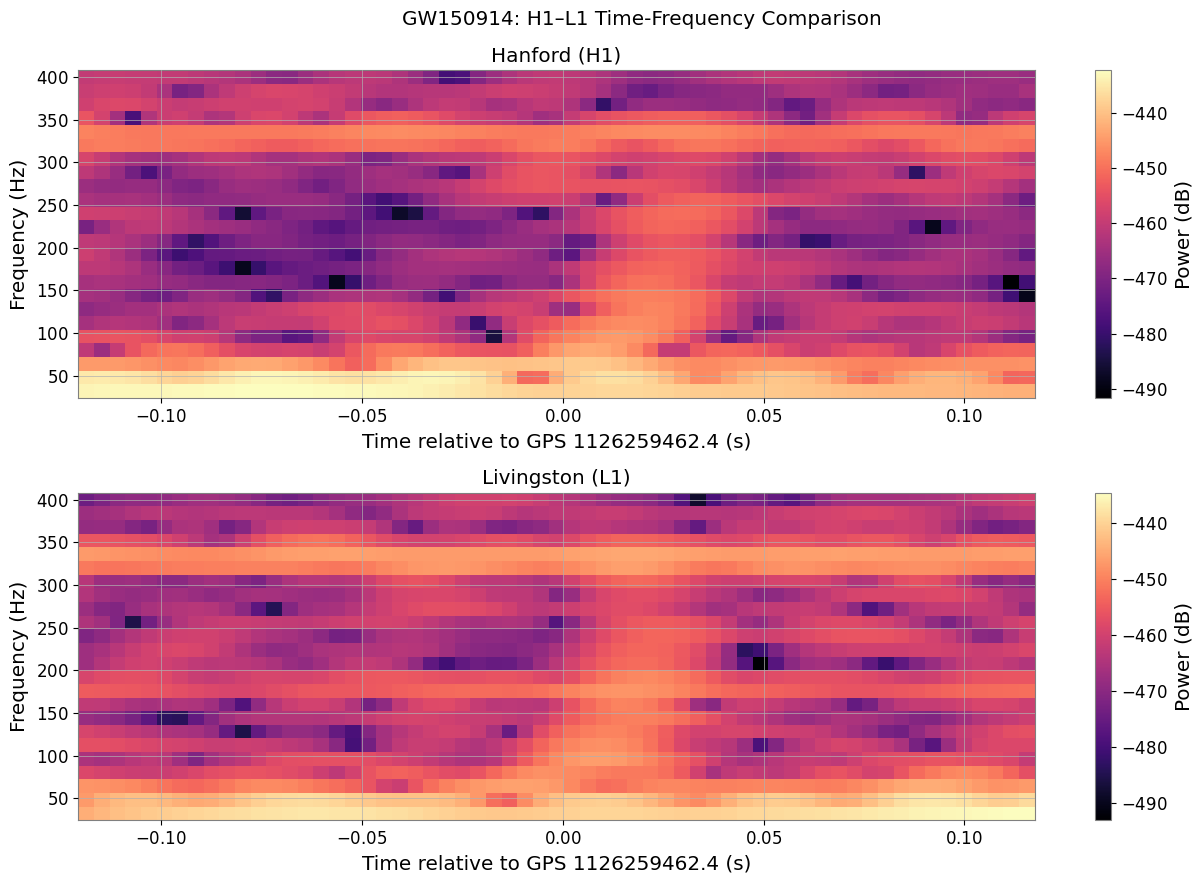

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

fs = float(h1.sample_rate.to_value("Hz"))
event_time = 1126259462.4

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

for ax, series, detector in [
    (axes[0], h1_filtered, "Hanford (H1)"),
    (axes[1], l1_filtered, "Livingston (L1)")
]:
    relative_time = np.asarray(series.times.value) - event_time
    data = np.asarray(series.value, dtype=float)

    mask = (relative_time >= -0.15) & (relative_time <= 0.15)
    event_data = data[mask]

    frequencies, times, power = spectrogram(
        event_data,
        fs=fs,
        window="hann",
        nperseg=256,
        noverlap=240,
        detrend="constant",
        scaling="density",
        mode="psd"
    )

    freq_mask = (frequencies >= 30) & (frequencies <= 400)

    mesh = ax.pcolormesh(
        times - 0.15,
        frequencies[freq_mask],
        10 * np.log10(power[freq_mask] + 1e-60),
        shading="auto",
        cmap="magma"
    )

    ax.set_title(detector)
    ax.set_ylabel("Frequency (Hz)")
    ax.set_xlabel("Time relative to GPS 1126259462.4 (s)")
    fig.colorbar(mesh, ax=ax, label="Power (dB)")

plt.suptitle("GW150914: H1–L1 Time-Frequency Comparison")
plt.tight_layout()
plt.show()

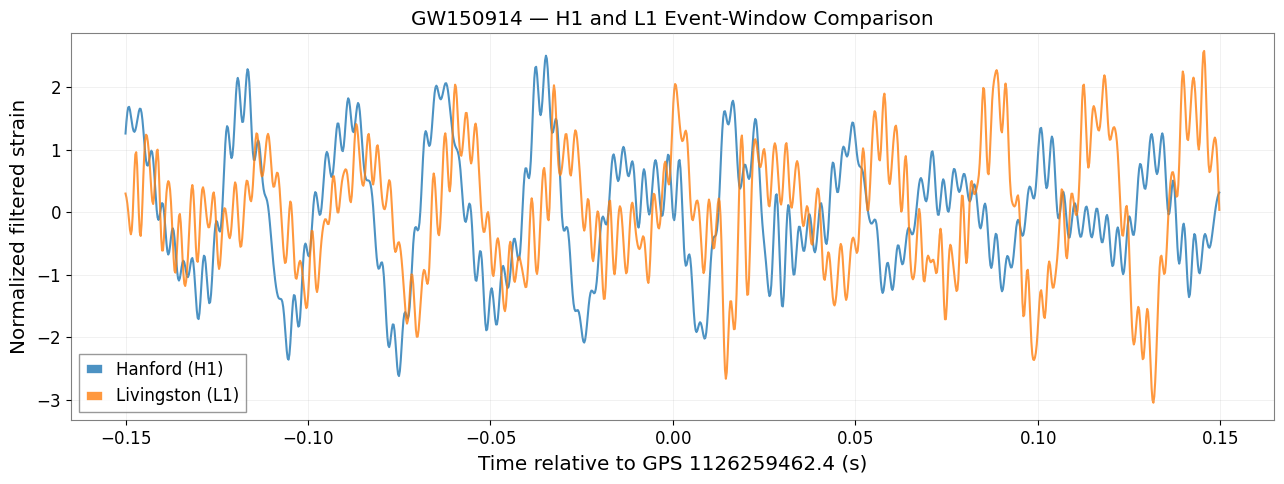

In [41]:
fs = float(h1.sample_rate.to_value("Hz"))
event_time = 1126259462.4

# Extract a short event window from both detectors
def extract_event(series, event_time, half_width=0.15):
    times = np.asarray(series.times.value)
    data = np.asarray(series.value, dtype=float)
    mask = (
        (times >= event_time - half_width) &
        (times <= event_time + half_width)
    )
    return times[mask] - event_time, data[mask]

t_h1, x_h1 = extract_event(h1_filtered, event_time)
t_l1, x_l1 = extract_event(l1_filtered, event_time)

# Normalize for shape comparison
x_h1 = x_h1 / (np.std(x_h1) + 1e-30)
x_l1 = x_l1 / (np.std(x_l1) + 1e-30)

plt.figure(figsize=(13, 5))
plt.plot(t_h1, x_h1, label="Hanford (H1)", alpha=0.8)
plt.plot(t_l1, x_l1, label="Livingston (L1)", alpha=0.8)
plt.xlabel("Time relative to GPS 1126259462.4 (s)")
plt.ylabel("Normalized filtered strain")
plt.title("GW150914 — H1 and L1 Event-Window Comparison")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Final addition: matched-filter analysis

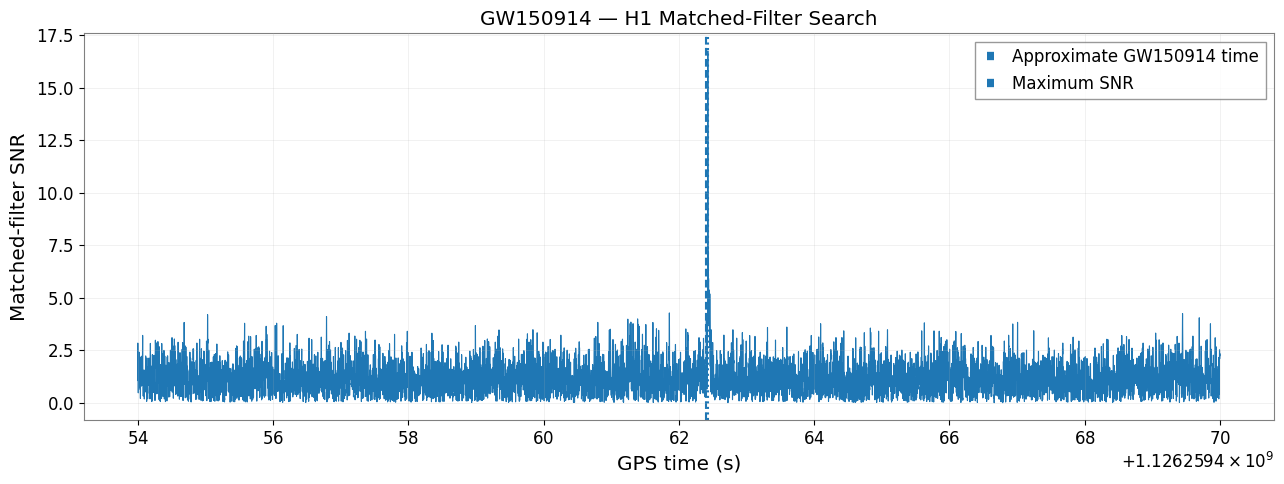

Maximum single-detector SNR: 16.76
Time of maximum SNR: 1126259462.429443 GPS


In [42]:
import numpy as np
import matplotlib.pyplot as plt

from pycbc.types import TimeSeries
from pycbc.psd import interpolate, inverse_spectrum_truncation
from pycbc.waveform import get_fd_waveform
from pycbc.filter import matched_filter

# Convert the existing H1 strain into a PyCBC time series
fs = int(h1.sample_rate.to_value("Hz"))
strain = np.asarray(h1.value, dtype=np.float64)

data = TimeSeries(
    strain,
    delta_t=1.0 / fs,
    epoch=float(h1.t0.value)
)

# Estimate the detector noise PSD
psd = data.psd(4)
psd = interpolate(psd, data.delta_f)
psd = inverse_spectrum_truncation(
    psd,
    int(4 * fs),
    low_frequency_cutoff=20
)

# Generate a theoretical binary-black-hole waveform
hp, hc = get_fd_waveform(
    approximant="IMRPhenomD",
    mass1=36,
    mass2=29,
    delta_f=data.delta_f,
    f_lower=20
)

# Match the template's frequency-domain length to the data
hp.resize(len(data) // 2 + 1)

# Calculate matched-filter SNR
snr = matched_filter(
    hp,
    data,
    psd=psd,
    low_frequency_cutoff=20,
    high_frequency_cutoff=400
)

# Exclude edge regions affected by filter wraparound
snr = snr[len(snr) // 4: 3 * len(snr) // 4]

snr_times = snr.sample_times.numpy()
snr_values = np.abs(snr.numpy())
peak_idx = np.argmax(snr_values)

plt.figure(figsize=(13, 5))
plt.plot(snr_times, snr_values, linewidth=0.8)
plt.axvline(
    1126259462.4,
    linestyle="--",
    label="Approximate GW150914 time"
)
plt.axvline(
    snr_times[peak_idx],
    linestyle=":",
    label="Maximum SNR"
)
plt.xlabel("GPS time (s)")
plt.ylabel("Matched-filter SNR")
plt.title("GW150914 — H1 Matched-Filter Search")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Maximum single-detector SNR: {snr_values[peak_idx]:.2f}")
print(f"Time of maximum SNR: {snr_times[peak_idx]:.6f} GPS")

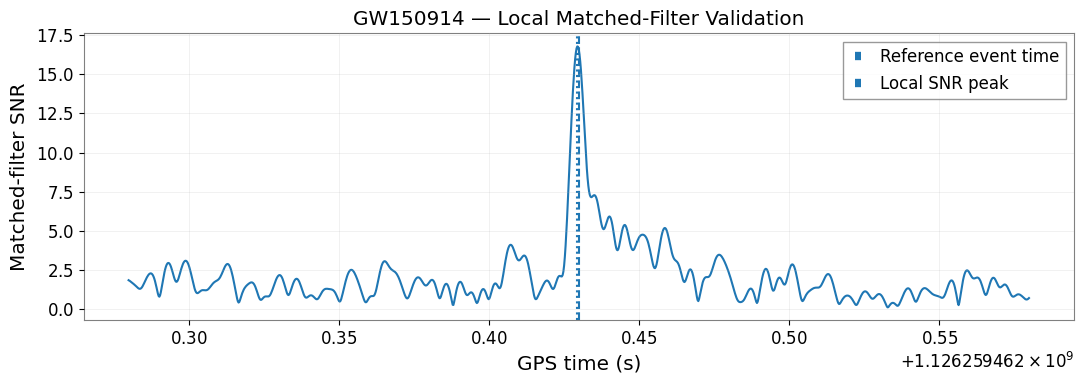

Local peak SNR: 16.76
Local peak GPS time: 1126259462.429443
Offset from reference: -0.56 ms


In [43]:
import numpy as np
import matplotlib.pyplot as plt

snr_times = np.asarray(snr.sample_times.numpy())
snr_values = np.abs(np.asarray(snr.numpy()))

event_time = 1126259462.43
window = 0.15

mask = np.abs(snr_times - event_time) <= window

if not np.any(mask):
    print("No SNR samples found in the event window.")
else:
    local_times = snr_times[mask]
    local_snr = snr_values[mask]

    peak_idx = np.argmax(local_snr)
    peak_time = local_times[peak_idx]
    peak_value = local_snr[peak_idx]

    plt.figure(figsize=(11, 4))
    plt.plot(local_times, local_snr)
    plt.axvline(
        event_time, linestyle="--",
        label="Reference event time"
    )
    plt.axvline(
        peak_time, linestyle=":",
        label="Local SNR peak"
    )
    plt.xlabel("GPS time (s)")
    plt.ylabel("Matched-filter SNR")
    plt.title("GW150914 — Local Matched-Filter Validation")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f"Local peak SNR: {peak_value:.2f}")
    print(f"Local peak GPS time: {peak_time:.6f}")
    print(f"Offset from reference: {(peak_time-event_time)*1000:.2f} ms")